# 13 — Does survival analysis actually beat regression? A censoring experiment

**Why this notebook exists.** This project's core argument is that predicting RUL is a survival problem because of *right censoring*: in a real fleet, many engines haven't failed yet when the model is built, and a plain regressor can't use them correctly. But every C-MAPSS training engine runs to failure, so the training data never contains that situation. (The one form of censoring tried earlier — marking rows above the 125-cycle cap as censored — was rejected because it broke the Weibull model; see `labeling.py`.) Until now the argument was reasoned, not measured.

This notebook **creates** realistic censoring in the training set and measures what happens.

**Setup**
- **Censoring mechanism** (`cross_validation.sample_administrative_censoring`): administrative censoring, as in a fleet observed up to a fixed date. Each engine gets an observation window $C_i = s \cdot u_i$, with $u_i \sim \text{Uniform}(0.5, 1.5)$ drawn independently of its lifetime; an engine is censored when $C_i$ is shorter than its life. Because $u_i$ is independent of lifetime, censoring is non-informative per engine — the assumption survival models rely on. The fleet-wide scale $s$ is set so exactly the target fraction of engines is censored.
- **Labels** (`cross_validation.build_censored_train_frame`): censored engines lose every row after their window; a remaining row with $t$ cycles left in the window gets `duration = t, event = 0` if $t < 125$, or `duration = 125, event = 1` if $t \ge 125$ (its capped RUL is then known exactly, matching the project's default labeling).
- **Censoring levels:** 0%, 25%, 50%, 75% of the 100 training engines; 5 random draws per level (one at 0%, which has no randomness).
- **Approaches**, all trained on the same censored data with the same features as Phase 6:

| Approach | Treatment of engines that haven't failed |
|---|---|
| **RSF** (survival) | used properly: "survived at least $t$ more cycles" |
| **Cox PH**, **Weibull AFT** (survival) | same; curated 25 features, as in Phases 3–4 |
| **Regression: drop censored** | discarded — train only on engines that failed |
| **Regression: censoring = failure** | pretend the engine failed when observation stopped |

  Both regressions are random forests with the RSF's hyperparameters (100 trees, `min_samples_leaf=30`, `max_features="sqrt"`, `row_stride=3`), so the only difference from RSF is how censoring is handled.
- **Evaluation:** the unchanged official FD001 test set (100 engines); test C-index, RMSE, MAE, NASA score, late rate, and mean error (predicted − true; negative = predicting too little life).

**Hypothesis, written before running:** as censoring increases, both regression approaches degrade faster than RSF, mainly in C-index and RMSE. *Decision rule:* the survival advantage is confirmed if, at 50% censoring, RSF's mean test C-index and RMSE both beat the better of the two regressions by more than the larger across-draw standard deviation. Two complications were anticipated: "censoring = failure" is biased toward early predictions, which the NASA score penalizes lightly, so it might look acceptable on NASA while losing elsewhere; and Weibull might blow up again given many censored rows.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import WeibullAFTFitter
from lifelines.utils import concordance_index
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import cross_validation, data_loading, evaluation, features, labeling, models, plotting

plotting.style()
SUBSET, CAP, DURATION_EPS, ROW_STRIDE = "FD001", 125, 1e-3, 3
LEVELS = [0.0, 0.25, 0.5, 0.75]
SEEDS = [0, 1, 2, 3, 4]
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")

# Features are built once on the full trajectories; censoring then drops
# later rows. Features are backward-looking, so this equals featurizing the
# truncated trajectories (checked in tests/test_cross_validation.py).
full_train = features.build_feature_matrix(
    labeling.build_train_survival_frame(cmapss.train, cap=CAP), kept_sensors=kept_sensors)

curated_cols = ["cycle_count"]
for s in kept_sensors:
    curated_cols += [f"{s}_roll15_mean", f"{s}_roll15_slope"]
META_COLS = {"unit_number", "time_cycles", "RUL", "duration", "event", "engine_censored"}
full_cols = [c for c in full_train.columns if c not in META_COLS]

test_survival = labeling.build_test_survival_frame(
    features.build_feature_matrix(cmapss.test, kept_sensors=kept_sensors), cmapss.rul)
y_true = test_survival["true_rul"].values
print(f"{full_train.unit_number.nunique()} training engines, {len(full_cols)} RSF/regression features, "
      f"{len(curated_cols)} Cox/Weibull features, {len(y_true)} test engines")

100 training engines, 229 RSF/regression features, 25 Cox/Weibull features, 100 test engines


## 1. The censoring mechanism, checked

Before using it, check that the simulated censoring behaves as intended: the right number of engines censored, windows shorter than lifetimes, and — the property that matters for survival models — window lengths that don't track lifetimes.

In [3]:
lives = cmapss.train.groupby("unit_number")["time_cycles"].max()
rows = []
for level in LEVELS[1:]:
    cens = cross_validation.sample_administrative_censoring(cmapss.train, level, random_state=0)
    frame = cross_validation.build_censored_train_frame(full_train, cens, cap=CAP)
    windows = pd.Series(cens)
    rows.append({
        "censored_fraction": level,
        "engines_censored": len(cens),
        "rows_kept": len(frame),
        "censored_rows (event=0)": int((frame.event == 0).sum()),
        "median_window / median_life (censored engines)": round(windows.median() / lives[windows.index].median(), 2),
    })
display(pd.DataFrame(rows))

# Independence check: the per-engine draw u_i must not track lifetime.
rng_check = np.random.default_rng(0)
u = rng_check.uniform(0.5, 1.5, size=len(lives))
print(f"correlation(u_i, lifetime) for seed 0: {np.corrcoef(u, lives.values)[0, 1]:+.3f}  (should be ~0)")

,censored_fraction,engines_censored,rows_kept,censored_rows (event=0),median_window / median_life (censored engines)
0,0.25,25,19300,3125,0.78
1,0.50,50,17751,6053,0.77
2,0.75,75,14953,8611,0.67


correlation(u_i, lifetime) for seed 0: +0.089  (should be ~0)


## 2. Run every approach at every censoring level

16 conditions (one at 0%, five draws at each of 25/50/75%), five approaches each, all scored on the official test set. About a minute per condition.

In [4]:
def regressor():
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=30, max_features="sqrt",
                                 random_state=42, n_jobs=-1)


def score(approach, pred, level, seed, n_censored):
    pred = np.asarray(pred, dtype=float)
    r = evaluation.evaluate_rul_predictions(y_true, pred, model_name=approach)
    r.update(approach=approach, level=level, seed=seed, n_censored=n_censored,
             test_cindex=concordance_index(y_true, pred), mean_error=float(np.mean(pred - y_true)))
    return r


results = []
t_start = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # routine lifelines/sklearn advisories
    for level in LEVELS:
        for seed in (SEEDS if level > 0 else [0]):
            cens = cross_validation.sample_administrative_censoring(cmapss.train, level, random_state=seed)
            frame = cross_validation.build_censored_train_frame(full_train, cens, cap=CAP)
            n_cens = len(cens)

            # Survival models: use censored rows as censored.
            rsf = models.fit_random_survival_forest(frame, full_cols, row_stride=ROW_STRIDE,
                                                    duration_eps=DURATION_EPS, random_state=42)
            results.append(score("RSF", models.predict_rul_from_survival(rsf, test_survival[full_cols])["pred_rul"],
                                 level, seed, n_cens))

            scaler = StandardScaler().fit(frame[curated_cols])
            frame_s = frame.copy(); frame_s[curated_cols] = scaler.transform(frame[curated_cols])
            test_s = test_survival.copy(); test_s[curated_cols] = scaler.transform(test_survival[curated_cols])

            cox = models.fit_cox_ph(frame_s, curated_cols, penalizer=0.1)
            results.append(score("Cox PH", cox.predict_expectation(test_s[curated_cols]).values, level, seed, n_cens))

            aft_df = frame_s.copy(); aft_df["duration"] = aft_df["duration"] + DURATION_EPS
            aft = WeibullAFTFitter(penalizer=0.1).fit(aft_df[curated_cols + ["duration", "event"]],
                                                       duration_col="duration", event_col="event")
            results.append(score("Weibull AFT", aft.predict_percentile(test_s[curated_cols], p=0.5).values,
                                 level, seed, n_cens))

            # Regression baselines: same rows (same stride), two ways of handling censoring.
            sub = frame.iloc[::ROW_STRIDE]
            failed = sub[~sub.engine_censored]
            reg_drop = regressor().fit(failed[full_cols], failed["duration"])
            results.append(score("Regression: drop censored", reg_drop.predict(test_survival[full_cols]),
                                 level, seed, n_cens))
            reg_naive = regressor().fit(sub[full_cols], sub["duration"])  # censored durations taken as failures
            results.append(score("Regression: censoring = failure", reg_naive.predict(test_survival[full_cols]),
                                 level, seed, n_cens))
            print(f"censored {level:.0%} (draw {seed}): {n_cens:3d} engines censored — "
                  f"{time.time() - t_start:5.0f}s elapsed")

results = pd.DataFrame(results)
results.to_csv(PROCESSED_DIR / "censoring_experiment_fd001.csv", index=False)
print(f"\nSaved {len(results)} rows to {PROCESSED_DIR / 'censoring_experiment_fd001.csv'}")

censored 0% (draw 0):   0 engines censored —    63s elapsed


censored 25% (draw 0):  25 engines censored —   112s elapsed


censored 25% (draw 1):  25 engines censored —   158s elapsed


censored 25% (draw 2):  25 engines censored —   209s elapsed


censored 25% (draw 3):  25 engines censored —   284s elapsed


...

censored 75% (draw 0):  75 engines censored —   604s elapsed


censored 75% (draw 1):  75 engines censored —   642s elapsed


censored 75% (draw 2):  75 engines censored —   683s elapsed


censored 75% (draw 3):  75 engines censored —   722s elapsed


censored 75% (draw 4):  75 engines censored —   765s elapsed

Saved 80 rows to ..\data\processed\censoring_experiment_fd001.csv


## 3. Results
Mean ± standard deviation across the five censoring draws (the 0% row has a single run).

In [5]:
APPROACHES = ["RSF", "Regression: drop censored", "Regression: censoring = failure", "Cox PH", "Weibull AFT"]
METRICS = ["test_cindex", "rmse", "mae", "nasa_score_mean", "late_prediction_rate", "mean_error"]

summary = results.groupby(["level", "approach"])[METRICS].agg(["mean", "std"])
for level in LEVELS:
    t = summary.loc[level].reindex(APPROACHES)
    table = pd.DataFrame({m: [f"{a:.3f} ± {b:.3f}" if pd.notna(b) else f"{a:.3f}"
                              for a, b in zip(t[(m, "mean")], t[(m, "std")])] for m in METRICS},
                         index=APPROACHES)
    print(f"\n=== {level:.0%} of training engines censored ===")
    display(table)


=== 0% of training engines censored ===


,test_cindex,rmse,mae,nasa_score_mean,late_prediction_rate,mean_error
RSF,0.858,16.268,12.039,4.511,0.620,2.445
Regression: drop censored,0.858,16.311,12.189,4.545,0.660,3.074
Regression: censoring = failure,0.858,16.311,12.189,4.545,0.660,3.074
Cox PH,0.821,21.930,16.809,15.505,0.510,0.982
Weibull AFT,0.820,23.167,18.231,12.595,0.470,-2.137



=== 25% of training engines censored ===


,test_cindex,rmse,mae,nasa_score_mean,late_prediction_rate,mean_error
RSF,0.857 ± 0.003,16.368 ± 0.310,12.065 ± 0.219,4.649 ± 0.436,0.588 ± 0.028,2.114 ± 0.758
Regression: drop censored,0.857 ± 0.004,16.480 ± 0.384,12.184 ± 0.275,4.316 ± 0.142,0.566 ± 0.026,0.751 ± 1.235
Regression: censoring = failure,0.850 ± 0.002,17.846 ± 0.838,12.976 ± 0.613,4.757 ± 0.557,0.444 ± 0.039,-4.158 ± 0.927
Cox PH,0.817 ± 0.002,22.223 ± 0.162,16.721 ± 0.195,16.437 ± 2.870,0.518 ± 0.026,0.467 ± 1.486
Weibull AFT,0.818 ± 0.003,23.482 ± 0.251,18.225 ± 0.178,13.888 ± 1.481,0.484 ± 0.038,-2.152 ± 1.763



=== 50% of training engines censored ===


,test_cindex,rmse,mae,nasa_score_mean,late_prediction_rate,mean_error
RSF,0.852 ± 0.003,17.276 ± 0.292,12.800 ± 0.392,5.746 ± 0.548,0.592 ± 0.020,2.786 ± 1.072
Regression: drop censored,0.851 ± 0.004,17.398 ± 0.504,12.843 ± 0.307,4.890 ± 0.562,0.500 ± 0.056,-1.347 ± 1.610
Regression: censoring = failure,0.839 ± 0.003,23.129 ± 1.088,17.067 ± 0.774,9.793 ± 1.440,0.290 ± 0.033,-11.741 ± 1.339
Cox PH,0.812 ± 0.005,22.798 ± 0.400,17.015 ± 0.413,18.623 ± 3.687,0.544 ± 0.052,0.474 ± 2.044
Weibull AFT,0.814 ± 0.004,23.868 ± 0.349,18.388 ± 0.151,15.534 ± 1.482,0.494 ± 0.035,-1.566 ± 1.780



=== 75% of training engines censored ===


,test_cindex,rmse,mae,nasa_score_mean,late_prediction_rate,mean_error
RSF,0.840 ± 0.003,19.004 ± 0.691,14.235 ± 0.576,9.047 ± 2.069,0.618 ± 0.050,4.514 ± 1.811
Regression: drop censored,0.837 ± 0.011,19.132 ± 1.201,14.397 ± 1.126,6.288 ± 1.051,0.442 ± 0.038,-2.381 ± 1.656
Regression: censoring = failure,0.828 ± 0.006,31.295 ± 1.027,24.232 ± 1.245,24.810 ± 2.768,0.164 ± 0.030,-21.679 ± 1.726
Cox PH,0.806 ± 0.006,23.334 ± 0.656,17.364 ± 0.733,24.375 ± 7.158,0.570 ± 0.037,1.397 ± 2.209
Weibull AFT,0.809 ± 0.005,24.622 ± 0.247,18.842 ± 0.187,19.692 ± 3.632,0.516 ± 0.047,-0.549 ± 2.660


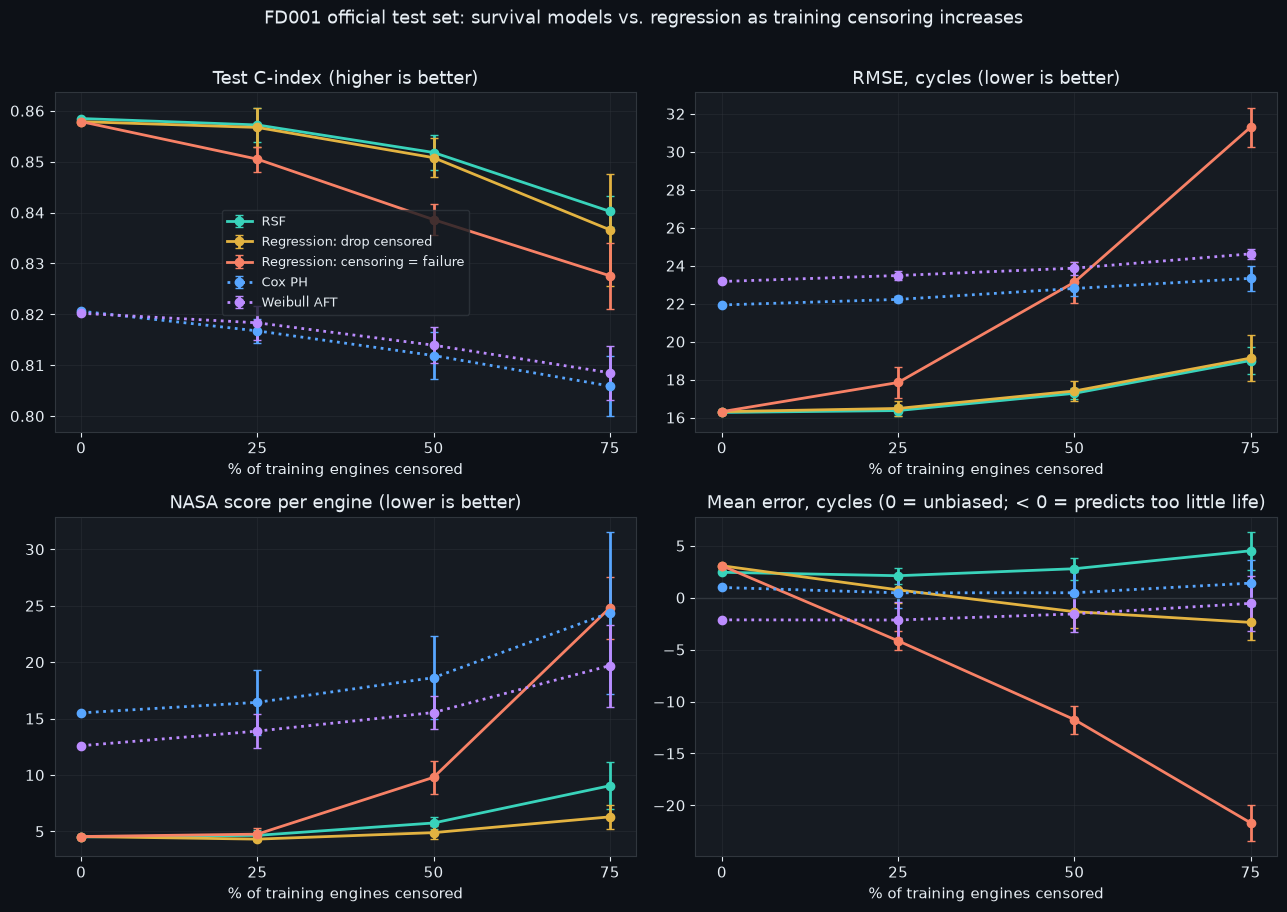

In [6]:
colours = {"RSF": plotting.TEAL, "Regression: drop censored": plotting.GOLD,
           "Regression: censoring = failure": plotting.C1, "Cox PH": plotting.C0, "Weibull AFT": plotting.PALETTE[4]}
panels = [("test_cindex", "Test C-index (higher is better)"), ("rmse", "RMSE, cycles (lower is better)"),
          ("nasa_score_mean", "NASA score per engine (lower is better)"),
          ("mean_error", "Mean error, cycles (0 = unbiased; < 0 = predicts too little life)")]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
x = np.array(LEVELS) * 100
for ax, (metric, title) in zip(axes.ravel(), panels):
    for approach in APPROACHES:
        g = results[results.approach == approach].groupby("level")[metric]
        mean, std = g.mean().reindex(LEVELS).values, g.std().reindex(LEVELS).fillna(0).values
        style = "-" if approach in ("RSF",) or approach.startswith("Regression") else ":"
        ax.errorbar(x, mean, yerr=std, marker="o", linestyle=style, linewidth=2, capsize=3,
                    color=colours[approach], label=approach)
    if metric == "mean_error":
        ax.axhline(0, color=plotting.GRID, linewidth=1)
    ax.set_title(title); ax.set_xlabel("% of training engines censored"); ax.set_xticks(x)
axes[0, 0].legend(fontsize=9)
fig.suptitle("FD001 official test set: survival models vs. regression as training censoring increases", y=1.01)
plt.tight_layout(); plt.show()

In [7]:
# The decision rule, applied mechanically.
at50 = summary.loc[0.5]
best_reg_c = max(at50.loc["Regression: drop censored", ("test_cindex", "mean")],
                 at50.loc["Regression: censoring = failure", ("test_cindex", "mean")])
best_reg_rmse = min(at50.loc["Regression: drop censored", ("rmse", "mean")],
                    at50.loc["Regression: censoring = failure", ("rmse", "mean")])
rsf_c, rsf_rmse = at50.loc["RSF", ("test_cindex", "mean")], at50.loc["RSF", ("rmse", "mean")]
c_margin_needed = at50[("test_cindex", "std")].loc[["RSF", "Regression: drop censored", "Regression: censoring = failure"]].max()
rmse_margin_needed = at50[("rmse", "std")].loc[["RSF", "Regression: drop censored", "Regression: censoring = failure"]].max()

c_ok = rsf_c - best_reg_c > c_margin_needed
rmse_ok = best_reg_rmse - rsf_rmse > rmse_margin_needed
print(f"At 50% censoring: RSF C-index {rsf_c:.3f} vs best regression {best_reg_c:.3f} "
      f"(margin {rsf_c - best_reg_c:+.3f}, needed > {c_margin_needed:.3f}) -> {'met' if c_ok else 'NOT met'}")
print(f"                  RSF RMSE    {rsf_rmse:.2f} vs best regression {best_reg_rmse:.2f} "
      f"(margin {best_reg_rmse - rsf_rmse:+.2f}, needed > {rmse_margin_needed:.2f}) -> {'met' if rmse_ok else 'NOT met'}")
print(f"\nPre-registered survival advantage over BOTH regressions: {'CONFIRMED' if c_ok and rmse_ok else 'NOT confirmed'}")

# Stability: spread across censoring draws, RSF vs the regression that drops censored engines.
for level in [0.5, 0.75]:
    s = summary.loc[level]
    print(f"{level:.0%} censored — C-index std: RSF {s.loc['RSF', ('test_cindex', 'std')]:.3f} vs "
          f"drop-censored regression {s.loc['Regression: drop censored', ('test_cindex', 'std')]:.3f}; "
          f"RMSE std: {s.loc['RSF', ('rmse', 'std')]:.2f} vs {s.loc['Regression: drop censored', ('rmse', 'std')]:.2f}")

At 50% censoring: RSF C-index 0.852 vs best regression 0.851 (margin +0.001, needed > 0.004) -> NOT met
                  RSF RMSE    17.28 vs best regression 17.40 (margin +0.12, needed > 1.09) -> NOT met

Pre-registered survival advantage over BOTH regressions: NOT confirmed
50% censored — C-index std: RSF 0.003 vs drop-censored regression 0.004; RMSE std: 0.29 vs 0.50
75% censored — C-index std: RSF 0.003 vs drop-censored regression 0.011; RMSE std: 0.69 vs 1.20


## 4. Verdict

**The pre-registered hypothesis is only partly confirmed — and the part that fails is informative.**

**Confirmed: survival analysis decisively beats treating censoring as failure.** The common mistake of labelling an unfinished engine as if it failed when observation stopped degrades fast as censoring grows. At 50% censoring its RMSE is about 23 cycles versus RSF's 17, its test C-index 0.839 versus 0.852, and its NASA score per engine about 9.8 versus 5.7; at 75% the RMSE gap widens to about 31 versus 19. The mean-error panel shows why: it learns to predict too little life (about −12 cycles at 50%, −22 at 75%), exactly the bias the survival framing predicts. Its *late-prediction rate* falls to 16–29% — it looks "safe", but only because it is systematically early.

**Not confirmed: a regression that simply drops unfinished engines is essentially tied with RSF.** On test C-index and RMSE the two are within noise at every censoring level (50%: C-index 0.852 vs 0.851, RMSE 17.3 vs 17.4), and the drop-censored regression actually has the **better NASA score** (50%: 4.9 vs 5.7 per engine; 75%: 6.3 vs 9.0). RSF drifts slightly *late* as censoring grows (mean error +2.8 at 50%, +4.5 at 75%), which the NASA score punishes; the drop-censored regression is nearly unbiased. So the decision rule — RSF beating *both* regressions by more than the noise at 50% — is **not met**.

**Why dropping censored engines works this well here.** Discarding unfinished engines biases training toward short-lived engines, but the 125-cycle cap mutes that bias: every row more than 125 cycles from failure has the same capped target regardless of the engine's total life, so losing long-lived engines removes little target information. The selection bias that makes "train on completed failures only" dangerous in general is largely absorbed by the cap in this setup.

**Where RSF still has a real edge: consistency.** Across censoring draws, RSF's test C-index varies about a third as much as the drop-censored regression's at 75% censoring (std 0.003 vs 0.011), and its RMSE spread is smaller too — it uses every engine, so it depends less on *which* engines happened to be censored. It also uses all the data rather than discarding up to three quarters of the fleet.

**Cox and Weibull** degrade gradually as censoring increases (they were never close to RSF on this data), and Weibull did *not* blow up under engine-level censoring — unlike the earlier capped-row censoring, these censored rows are short windows, not a mass of rows all censored at exactly 125.

**What this changes in the project's claims.** The framing "regression is wrong under censoring" is true for the naive version (treating censoring as failure) and is now measured. It is *not* true, on this dataset, that survival analysis beats every regression strategy: a careful regression that discards unfinished engines matches it on accuracy and beats it on the NASA score, at the cost of throwing away data and being less stable. The honest case for the survival models in this project is therefore: they use all engines correctly, they are more stable under censoring, they give calibrated intervals (Weibull) that regression doesn't — not that they are uniquely accurate.

**Limitations.** One dataset (FD001), one censoring mechanism, one regressor family with RSF-matched hyperparameters (not separately tuned), the 125-cycle cap (which, as above, helps the drop-censored regression), and an uncensored official test set. An uncapped target or an informative-censoring mechanism would be the natural next tests.